# レポート：地方移住促進に向けた「子育てしやすい地域」の特徴分析
担当者：齋藤太知  
学生番号：1264820212  
依頼元の組織：移住支援コンサルティング株式会社  
読み手：事業企画部 部長  

## 1. 目的と問い
* **この組織が知りたいこと**：子育て世代の地方移住を促す新しいPRキャンペーンを企画するため、日本のどの地域で出生率が高く、どのような環境（経済状況や保育環境など）と関係しているのかを把握したい。
* **今回の問い**：
  1. 合計特殊出生率が「1.5以上」と高い都道府県と、「1.3未満」と低い都道府県はどこに集中しているか？
  2. 出生率の高さは、「所得の低さ」や「保育所の充実度」と関係があるのか？

## 2. データの読み込みと概要確認
授業で提供された47都道府県の統計データ `japan.csv` を読み込む。
元の統計年次や詳細な調査定義が記載されていないため、本レポートでは「提供データ時点での都道府県間の比較傾向」として分析を行う（現在の最新値とは断定しない）。

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# CSVファイルの読み込み
df = pd.read_csv('japan.csv')

# データの行数・列数と、今回使用する主な列の先頭5行を確認
print(f"データ件数: {len(df)} 都道府県, 列数: {len(df.columns)} 列")
df[['都道府県', 'Prefecture', '総人口', '合計特殊出生率', '1人当たり県民所得（平成27年基準）', '保育所等数']].head()

データ件数: 47 都道府県, 列数: 92 列


,都道府県,Prefecture,総人口,合計特殊出生率,1人当たり県民所得（平成27年基準）,保育所等数
0,北海道,Hokkaido,5140000,1.20,2832,1075
1,青森県,Aomori,1204000,1.31,2628,472
2,岩手県,Iwate,1181000,1.30,2781,393
3,宮城県,Miyagi,2280000,1.15,2943,506
4,秋田県,Akita,930000,1.22,2713,272


## 3. 分析①：合計特殊出生率が高い地域と低い地域の抽出
前回の調査を引き継ぎ、forループと条件分岐（if文）を用いて、出生率が「1.5以上」の都道府県と「1.3未満」の都道府県を抽出・カウントする。

In [2]:
high_list = []
low_list = []

for index, row in df.iterrows():
    rate = row['合計特殊出生率']
    pref_ja = row['都道府県']
    pref_en = row['Prefecture']
    
    if rate >= 1.5:
        high_list.append((pref_ja, pref_en, rate))
    elif rate < 1.3:
        low_list.append((pref_ja, pref_en, rate))

print(f"【出生率が高い都道府県 (1.5以上)：計 {len(high_list)} 件】")
for ja, en, r in high_list:
    print(f"  {ja} ({en}): {r}")

print(f"\n【出生率が低い都道府県 (1.3未満)：計 {len(low_list)} 件】")
for ja, en, r in low_list:
    print(f"  {ja} ({en}): {r}")

【出生率が高い都道府県 (1.5以上)：計 11 件】
  福井県 (Fukui): 1.57
  鳥取県 (Tottori): 1.51
  島根県 (Shimane): 1.62
  香川県 (Kagawa): 1.51
  佐賀県 (Saga): 1.56
  長崎県 (Nagasaki): 1.6
  熊本県 (Kumamoto): 1.59
  大分県 (Oita): 1.54
  宮崎県 (Miyazaki): 1.64
  鹿児島県 (Kagoshima): 1.65
  沖縄県 (Okinawa): 1.8

【出生率が低い都道府県 (1.3未満)：計 9 件】
  北海道 (Hokkaido): 1.2
  宮城県 (Miyagi): 1.15
  秋田県 (Akita): 1.22
  埼玉県 (Saitama): 1.22
  千葉県 (Chiba): 1.21
  東京都 (Tokyo): 1.08
  神奈川県 (Kanagawa): 1.22
  京都府 (Kyoto): 1.22
  大阪府 (Osaka): 1.27


## 4. 分析②：上位5県と下位5県の視覚的な比較（棒グラフ）
文字の一覧だけでは高低差のインパクトが伝わりにくいため、出生率の上位5県と下位5県を並べ替えて横棒グラフで比較する（日本語フォントの文字化けを防ぐため、グラフ内は英語表記とする）。

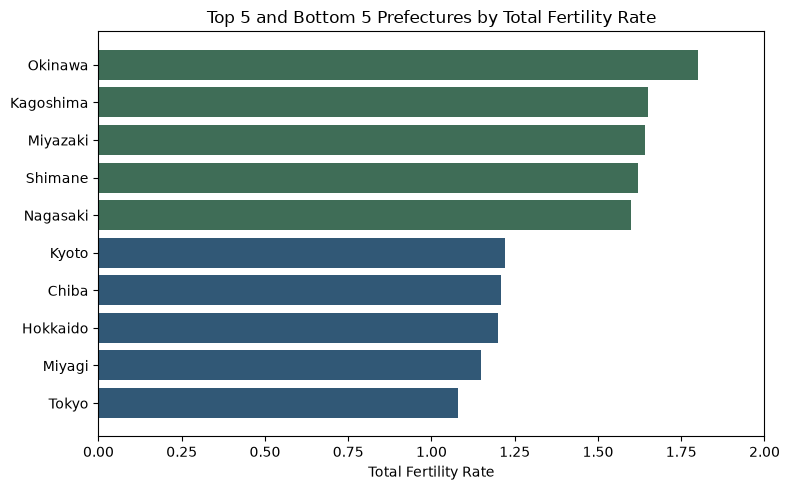

In [3]:
# 出生率が高い順に並べ替え
df_sorted = df.sort_values(by='合計特殊出生率', ascending=False)

# 上位5県と下位5県を結合
top_bottom = pd.concat([df_sorted.head(5), df_sorted.tail(5)])

plt.figure(figsize=(8, 5))
# 上位5県を緑色、下位5県を青色で色分け
colors = ['#3f6d57']*5 + ['#315876']*5
plt.barh(top_bottom['Prefecture'], top_bottom['合計特殊出生率'], color=colors)
plt.gca().invert_yaxis() # 1位を一番上に表示
plt.xlabel('Total Fertility Rate')
plt.title('Top 5 and Bottom 5 Prefectures by Total Fertility Rate')
plt.xlim(0, 2.0)
plt.tight_layout()
plt.show()

## 5. 分析③：出生率と他の指標との関係（散布図）
前回の課題であった「なぜ都市部で低く、地方で高いのか」の手がかりを得るため、以下の2つの指標と合計特殊出生率の関係を散布図で調べる。
1. **経済面**：1人当たり県民所得（平成27年基準）
2. **子育て環境面**：人口10万人あたりの保育所等数（総人口の違いによる影響を除くため、割合を計算して比較する）

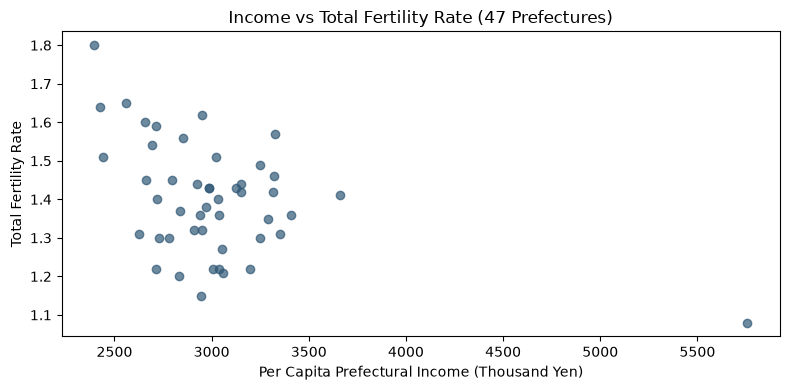

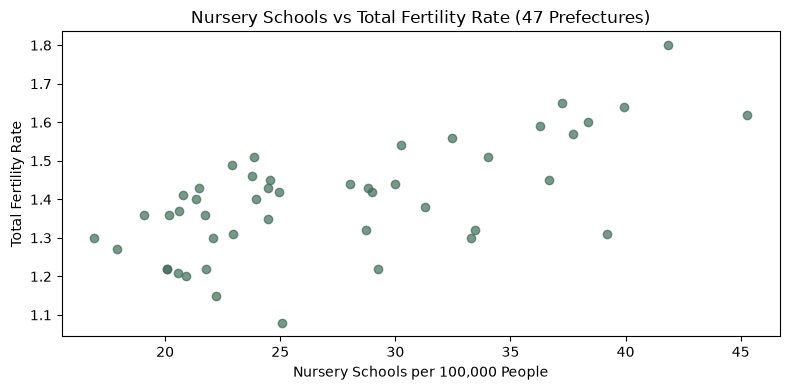

In [4]:
# 人口10万人あたりの保育所等数を計算
df['保育所数_10万人あたり'] = df['保育所等数'] / df['総人口'] * 100000

# 1つ目：1人当たり県民所得と出生率の散布図
plt.figure(figsize=(8, 4))
plt.scatter(df['1人当たり県民所得（平成27年基準）'], df['合計特殊出生率'], color='#315876', alpha=0.7)
plt.xlabel('Per Capita Prefectural Income (Thousand Yen)')
plt.ylabel('Total Fertility Rate')
plt.title('Income vs Total Fertility Rate (47 Prefectures)')
plt.tight_layout()
plt.show()

# 2つ目：人口10万人あたり保育所数と出生率の散布図
plt.figure(figsize=(8, 4))
plt.scatter(df['保育所数_10万人あたり'], df['合計特殊出生率'], color='#3f6d57', alpha=0.7)
plt.xlabel('Nursery Schools per 100,000 People')
plt.ylabel('Total Fertility Rate')
plt.title('Nursery Schools vs Total Fertility Rate (47 Prefectures)')
plt.tight_layout()
plt.show()

## 6. 結論と組織への提案・分析の限界

### わかったこと（結果の解釈）
1. **地域的な偏り**：出生率1.5以上の11件は沖縄県（1.80）や九州・中国地方などの西日本に集中し、1.3未満の9件は東京都（1.08）をはじめとする首都圏や大都市部に集中している。
2. **所得との関係（散布図1）**：多くの県は2,500〜3,500千円の間に分布しているが、全体として所得が高いほど出生率が下がる緩やかな右肩下がりの傾向が見られた。特に右下に大きく離れた東京都（所得5,757千円・出生率1.08）と、左上の沖縄県（所得2,396千円・出生率1.80）の対比が際立っている。
3. **保育所数との関係（散布図2）**：人口10万人あたりの保育所等数が増えるほど出生率も高くなる、明確な右肩上がりの傾向が確認できた。保育所数が20〜25か所付近の県では出生率が1.1〜1.4台にとどまる一方、35か所以上の県の多くは1.5以上を記録している。

### 事業企画部への提案
移住PRキャンペーンにおいては、単に「自然が豊か」と訴えるだけでなく、**「都市部より所得水準は低くても、人口あたりの保育所数が充実しており子育てしやすい環境がある」**というデータを根拠に、九州・中国地方などの自治体を移住先モデルとして提案すべきである。

### 分析の限界と前回からの改善点
* **分析の限界**：散布図で強い関連性が見られたものの、相関関係がそのまま因果関係（保育所を増やせば必ず出生率が上がる等）を証明するものではない。また、共働き率や住宅の広さ、祖父母との同居率など、他の要因も影響している可能性がある。
* **前回レポートからの改善点**：
  1. 依頼元（地方創生・移住支援コンサルティング会社）と読み手（事業企画部長）を明確にし、調査の目的を定義した。
  2. 横棒グラフと2種類の散布図を追加し、地域差と要因の傾向を視覚的に示した。
  3. 出生率単体の集計にとどまらず、所得や人口あたりの保育所数と掛け合わせて多角的に考察した。